In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

Palette = ['#ebc334', '#bd1041', '#76d5de', '#6250d6', '#48e348']
Tier_Order = ['hot desk', 'flex', 'dedicated desk', 'full time', 'private office']
Tier_Color = dict(zip(Tier_Order, Palette))
Graph_Color = ['#EA9F09', '#87cefa']
Edgecolor = ['#000000', '#FFFFFF']
Heatmap = ['PiYG', 'Blues']

# Information (raw data)

In [157]:
Directory = '/Users/josemenezes/Faculdade/Projetos/Projeto DM/Data-Mining-Project/Dataset/'
acdc_dataset = pd.read_csv(Directory + 'acdc_dataset.csv', sep=';')

# Data Description

In [158]:
acdc_dataset.head().T

,0,1,2,3,4
member_id,CW000001,CW000002,CW000003,CW000004,CW000005
age,38.0,38.0,43.0,38.0,45.0
gender,Female,Male,Male,F,Female
industry,Information Technology,Information Technology,Education,Legal,Information Technology
country,Portugal,Portugal,DE,portugal,United Kingdom
is_team_account,False,True,True,False,False
n_colleagues_on_account,0,2,1,0,0
plan_tier,flex,HOT_DESK,flex,flex,hot_desk
plan_days_per_week,3,2,3,3,2
membership_start,2021-08-01,2023-11-24,2021-12-03,2022-01-02,2023-10-24


In [159]:
acdc_dataset.tail().T

,15460,15461,15462,15463,15464
member_id,CW009828,CW005287,CW003868,CW013132,CW015101
age,29.0,19.0,28.0,32.0,46.0
gender,Female,Female,Female,Female,Male
industry,Unknown,Information Technology,Design & Creative,Legal,Information Technology
country,Spain,Germany,Portugal,Portugal,Portugal
is_team_account,False,False,True,False,False
n_colleagues_on_account,0,0,1,0,0
plan_tier,flex,private_office,hot_desk,dedicated_desk,flex
plan_days_per_week,3,7,2,5,3
membership_start,2022-12-09,2021-04-29,2023-12-27,2021-08-28,2022-02-04


In [160]:
acdc_dataset.shape

(15465, 31)

### Info() analysis

In [161]:
acdc_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

- 'lifetime_value', 'meeting_room_hours, 'plan_tier', 'country', 'gender' and 'age' have missing values.
- 'lifetime_value should be a numeric dtype but is an object.
- Date features are also stored as objects and must be converted to date or datetime.
- 'uses_print' should be boolean but is an int64.


### Describe() analysis

In [162]:
acdc_dataset.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


- age seems to have a few impossible values with a 149 years max and 1 year min.
- n_colleagues_on_account, days_since_last_visit, total_visits, meeting_room_hours, event_space_hours, guest_passes_issued and n_renewals all have negative values which are not possible.
- plan_days_per_week has impossible min of 0 and mas of 9, as we cannot have 0 days of usage per week neither can we have 9 days since a week only has 7.
- avg_weekly_visits has a unusual max value of 47.40, which would mean that a user is using the service more than 6 times a day.
- meeting_room_hours also has an strange and unusually high max value of 41220 hours, which is almost 5 years of usage, and we only have 3 years of data.
- uses_print is using 0 and 1 instead of a boolean and should be corrected.

In [163]:
acdc_dataset.describe(include=['object', 'bool']).T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
is_team_account,15465,2,False,11112
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
uses_meeting_rooms,15465,2,False,10202


- membership_end seems to have a placeholder value os 1970-01-01, which should be for users we active memberships. This is a common practice when there is no end date.
- gender is either very modern or has 10 incorrect recordings.

In [164]:
for col in ['gender', 'plan_tier', 'country', 'industry']:
    print(f'{col} ({acdc_dataset[col].nunique()} unique values)')
    print((acdc_dataset[col].value_counts(dropna=False, normalize=True) * 100).round(2).to_string())
    print()

gender (12 unique values)
gender
Female     47.94
Male       39.91
NaN         3.43
Other       3.01
female      1.09
F           0.92
 Female     0.91
M           0.89
male        0.85
 Male       0.83
other       0.10
 Other      0.06
O           0.05

plan_tier (19 unique values)
plan_tier
flex              33.51
hot_desk          32.16
full_time         15.02
dedicated_desk     9.58
private_office     4.07
Flex               0.89
FLEX               0.86
NaN                0.68
HOT_DESK           0.53
Hot Desk           0.52
hotdesk            0.51
fulltime           0.41
FULL_TIME          0.32
Full Time          0.25
DEDICATED_DESK     0.17
Dedicated Desk     0.16
dedicateddesk      0.12
Private Office     0.08
privateoffice      0.08
PRIVATE_OFFICE     0.06

country (33 unique values)
country
Portugal           64.40
United Kingdom      7.15
Germany             5.51
Spain               4.60
France              3.27
Netherlands         3.00
NaN                 2.78
Other (Europe) 

- the categorical variables have inconsistent labels for the same category, these must be adressed.

# Duplicates

In [165]:
print('Duplicated member_id:', acdc_dataset['member_id'].duplicated().sum())
print('Fully duplicated rows:',acdc_dataset.duplicated().sum())
print('Duplicated rows ignoring member_id:', acdc_dataset.drop(columns='member_id').duplicated().sum())

Duplicated member_id: 15
Fully duplicated rows: 15
Duplicated rows ignoring member_id: 182


- these results seem to show that there are users that are registred several times , 15 users that are fully duplicated and 15 users who have the same member id.

In [166]:
dup_ids = acdc_dataset[acdc_dataset['member_id'].duplicated(keep=False)].sort_values('member_id')
dup_ids.head(10).T

,959,15453,15454,1428,15462,3985,15461,5441,6011,15456
member_id,CW000935,CW000935,CW001390,CW001390,CW003868,CW003868,CW005287,CW005287,CW005845,CW005845
age,22.0,22.0,44.0,44.0,28.0,28.0,19.0,19.0,35.0,35.0
gender,Female,Female,Male,Male,Female,Female,Female,Female,Female,Female
industry,Unknown,Unknown,UNKNOWN,UNKNOWN,Design & Creative,Design & Creative,Information Technology,Information Technology,FINANCE,FINANCE
country,Portugal,Portugal,Portugal,Portugal,Portugal,Portugal,Germany,Germany,Portugal,Portugal
is_team_account,False,False,False,False,True,True,False,False,True,True
n_colleagues_on_account,0,0,0,0,1,1,0,0,3,3
plan_tier,FLEX,FLEX,hot_desk,hot_desk,hot_desk,hot_desk,private_office,private_office,dedicated_desk,dedicated_desk
plan_days_per_week,3,3,2,2,2,2,7,7,5,5
membership_start,2022-12-18,2022-12-18,28/10/2022,28/10/2022,2023-12-27,2023-12-27,2021-04-29,2021-04-29,2021-10-05,2021-10-05


- many duplicated users with different ids.

In [167]:
same_profile = acdc_dataset[acdc_dataset.drop(columns='member_id').duplicated(keep=False)]
same_profile.sort_values(['membership_start', 'age', 'total_visits']).head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
9791,CW009520,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
15228,CW015276,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
545,CW000530,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
12352,CW015227,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
3380,CW003279,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
15116,CW015289,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
1283,CW015110,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
9933,CW009657,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
6437,CW006262,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0
13967,CW015140,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0


- this shows that there are several user registred twice with different ids.

In [168]:
acdc_dataset = acdc_dataset.drop_duplicates()
acdc_dataset.shape

(15450, 31)

In [169]:
df_no_duplicates = acdc_dataset.drop_duplicates()                                   
df_no_duplicates = df_no_duplicates[~df_no_duplicates.drop(columns='member_id').duplicated(keep='first')]
df_no_duplicates = df_no_duplicates.set_index('member_id')

print('Duplicated index:', df_no_duplicates.index.duplicated().sum())
df_no_duplicates.shape

Duplicated index: 0


(15283, 30)

- we dropped all duplicated rows and users as well cleared users who had different entries with different ids.

# Missing Values

In [170]:
acdc_dataset.isna().sum()

member_id                         0
age                             557
gender                          530
industry                          0
country                         429
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1295
event_space_hours                 0
guest_passes_issued            1269
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [171]:
null_values = acdc_dataset.isnull().sum()
null_values = null_values[null_values > 0].sort_values(ascending=False)
null_values

meeting_room_hours     1295
guest_passes_issued    1269
lifetime_value         1040
age                     557
gender                  530
country                 429
plan_tier               105
dtype: int64

# Cleaning

### Age

In [172]:
acdc_dataset['age'] = acdc_dataset['age'].astype(float) #changing age type

### Gender

In [173]:
acdc_dataset['gender'].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [174]:
gender_dict = {
    'F': 'female',
    'M': 'male',                #fixing gender labels
    'O': 'Other'
               }

acdc_dataset['gender'] = acdc_dataset['gender'].replace(gender_dict)

acdc_dataset['gender'] = acdc_dataset['gender'].str.lower()

acdc_dataset['gender'] = acdc_dataset['gender'].str.strip()

acdc_dataset['gender'].unique()

array(['female', 'male', 'other', nan], dtype=object)

### Industry

In [175]:
acdc_dataset['industry'].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [176]:
industry_dict = {
    'realestate': 'real estate',
    'it': 'information technology',
    'tech': 'information technology'
}

s = (
    acdc_dataset['industry']
    .astype('string')
    .str.strip()
    .str.lower()
    .str.replace('/', ' & ', regex=False)
    .str.replace(r'\band\b', '&', regex=True)
    .str.replace(r'[-_]', ' ', regex=True)
    .str.replace(r'\s*&\s*', ' & ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

acdc_dataset['industry'] = s.replace(industry_dict)
acdc_dataset['industry'].unique()


<StringArray>
['information technology', 'education', 'legal', 'health', 'unknown', 'other', 'consulting', 'design & creative', 'finance', 'marketing & pr', 'real estate']
Length: 11, dtype: string

### Country

In [177]:
acdc_dataset['country'].unique()

array(['Portugal', 'DE', 'portugal', 'United Kingdom', 'Spain', 'Germany',
       'Netherlands', 'France', 'PT', 'Other (Europe)', 'Portucal', nan,
       'UK', 'Ireland', 'United kingdom', 'IE', 'portugal ',
       'Deutschland', 'ireland', 'germany', 'france', 'united kingdom',
       'other (europe)', 'U.K.', 'GB', 'ES', 'NL', 'España', 'Espana',
       'netherlands', 'spain', 'The Netherlands', 'FR', 'Holland'],
      dtype=object)

In [178]:
country_dict = {
    'portucal': 'portugal',
    'pt': 'portugal',
    'de': 'germany',
    'deutschland': 'germany',
    'uk': 'united kingdom',
    'u.k.': 'united kingdom',
    'gb': 'united kingdom',
    'ie': 'ireland',
    'es': 'spain',
    'españa': 'spain',
    'espana': 'spain',
    'fr': 'france',
    'nl': 'netherlands',
    'the netherlands': 'netherlands',
    'holland': 'netherlands'
}

# Standardize spelling/case first so that all variants can be mapped consistently.
acdc_dataset['country'] = (
    acdc_dataset['country']
    .astype('string')
    .str.strip()
    .str.lower()
    .replace(country_dict)
)

acdc_dataset['country'].unique()


<StringArray>
['portugal', 'germany', 'united kingdom', 'spain', 'netherlands', 'france', 'other (europe)', <NA>, 'ireland']
Length: 9, dtype: string

### Is_team_account

In [179]:
acdc_dataset['is_team_account'].unique() # everything good

array([False,  True])

### Dates

In [180]:
date_columns = ['membership_start', 'membership_end', 'last_badge_swipe']

def parse_mixed_dates(series):
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    european = pd.to_datetime(series, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(european)

for col in date_columns:
    acdc_dataset[col] = parse_mixed_dates(acdc_dataset[col])
    print(f'{col}: unparsed dates = {acdc_dataset[col].isna().sum()}')

# 1970-01-01 is the placeholder for "no end date yet": these members are still ACTIVE.
active_placeholder = acdc_dataset['membership_end'] == pd.Timestamp('1970-01-01')
acdc_dataset.loc[active_placeholder, 'membership_end'] = pd.NaT
acdc_dataset['is_active'] = active_placeholder.astype(bool)

print(f'\nActive members (membership_end = 1970-01-01): {active_placeholder.sum()} ({active_placeholder.mean() * 100:.1f}%)')
acdc_dataset[date_columns].dtypes


membership_start: unparsed dates = 0
membership_end: unparsed dates = 0
last_badge_swipe: unparsed dates = 0

Active members (membership_end = 1970-01-01): 3954 (25.6%)


membership_start    datetime64[ns]
membership_end      datetime64[ns]
last_badge_swipe    datetime64[ns]
dtype: object

In [205]:
# this will check for the implied data extraction date

active = acdc_dataset['is_active'] == True
valid_dslv = acdc_dataset['days_since_last_visit'].between(0, 998)
implied_reference = (acdc_dataset.loc[active & valid_dslv, 'last_badge_swipe']
                     + pd.to_timedelta(acdc_dataset.loc[active & valid_dslv, 'days_since_last_visit'], unit='D'))
implied_reference.value_counts(normalize=True).head(5).round(3)

2024-01-01    0.921
2023-12-31    0.065
2023-12-28    0.001
2024-01-06    0.001
2023-12-27    0.001
Name: proportion, dtype: float64

In [182]:
Reference_Date = pd.Timestamp('2024-01-01')

# Reference point of each member: end of membership (churned) or extraction date (active)
reference_point = acdc_dataset['membership_end'].fillna(Reference_Date)

In [183]:
date_checks = pd.DataFrame({
    'end_before_start': acdc_dataset['membership_end'] < acdc_dataset['membership_start'],
    'swipe_before_start': acdc_dataset['last_badge_swipe'] < acdc_dataset['membership_start'],
    'swipe_after_end': acdc_dataset['last_badge_swipe'] > acdc_dataset['membership_end'],
    'swipe_after_extraction': acdc_dataset['last_badge_swipe'] > Reference_Date,
    'end_after_extraction': acdc_dataset['membership_end'] > Reference_Date ,
})
summary = pd.DataFrame({'rows': date_checks.sum(), '%': (date_checks.mean() * 100).round(2)})
summary

,rows,%
end_before_start,152,0.98
swipe_before_start,94,0.61
swipe_after_end,213,1.38
swipe_after_extraction,34,0.22
end_after_extraction,0,0.00


### Plan_tier

In [184]:
acdc_dataset['plan_tier'].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

In [185]:
acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.lower()

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.replace('_', ' ')

plan_tier_dict = {
    'fulltime': 'full time',
    'hotdesk': 'hot desk',
    'privateoffice': 'private office',
    'dedicateddesk': 'dedicated desk'
}

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].replace(plan_tier_dict)

acdc_dataset['plan_tier'].unique()

array(['flex', 'hot desk', 'dedicated desk', 'full time',
       'private office', nan], dtype=object)

### Avg_weekly_visits

In [186]:
acdc_dataset['avg_weekly_visits'] = acdc_dataset['avg_weekly_visits'].astype(float)

### Entitled_visits_last_period

In [187]:
acdc_dataset['entitled_visits_last_period'] = acdc_dataset['entitled_visits_last_period'].astype(float)

### Meeting_room_hours / Event_space_hours / Guest_passes_issued

In [188]:
acdc_dataset['meeting_room_hours'] = acdc_dataset['meeting_room_hours'].astype(float)

acdc_dataset['event_space_hours'] = acdc_dataset['event_space_hours'].astype(float)

acdc_dataset['guest_passes_issued'] = acdc_dataset['guest_passes_issued'].astype(float)

### Uses_print

In [189]:
acdc_dataset['uses_print'].unique()

array([0, 1])

In [190]:
acdc_dataset['uses_print'] = acdc_dataset['uses_print'].astype(bool)

### Lifetime_value

In [191]:
acdc_dataset['lifetime_value'] = (
    acdc_dataset['lifetime_value']
    .str.replace('€', '', regex=False) # removing '€' and ',' to convert to float for metrics
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

# Information (cleaned Data)

In [192]:
acdc_dataset.dtypes

member_id                              object
age                                   float64
gender                                 object
industry                       string[python]
country                        string[python]
is_team_account                          bool
n_colleagues_on_account                 int64
plan_tier                              object
plan_days_per_week                      int64
membership_start               datetime64[ns]
membership_end                 datetime64[ns]
last_badge_swipe               datetime64[ns]
days_since_last_visit                   int64
total_visits                            int64
avg_weekly_visits                     float64
entitled_visits_last_period           float64
actual_visits_last_period               int64
meeting_room_hours                    float64
event_space_hours                     float64
guest_passes_issued                   float64
uses_meeting_rooms                       bool
uses_event_space                  

# Exploratory Data Analysis and Visualizations

The following section explores the cleaned dataset from a segmentation perspective. The aim is not only to describe the members, but to identify differences in value, activity, plan usage and service engagement that may later help distinguish meaningful customer groups.

## Member demographic distribution

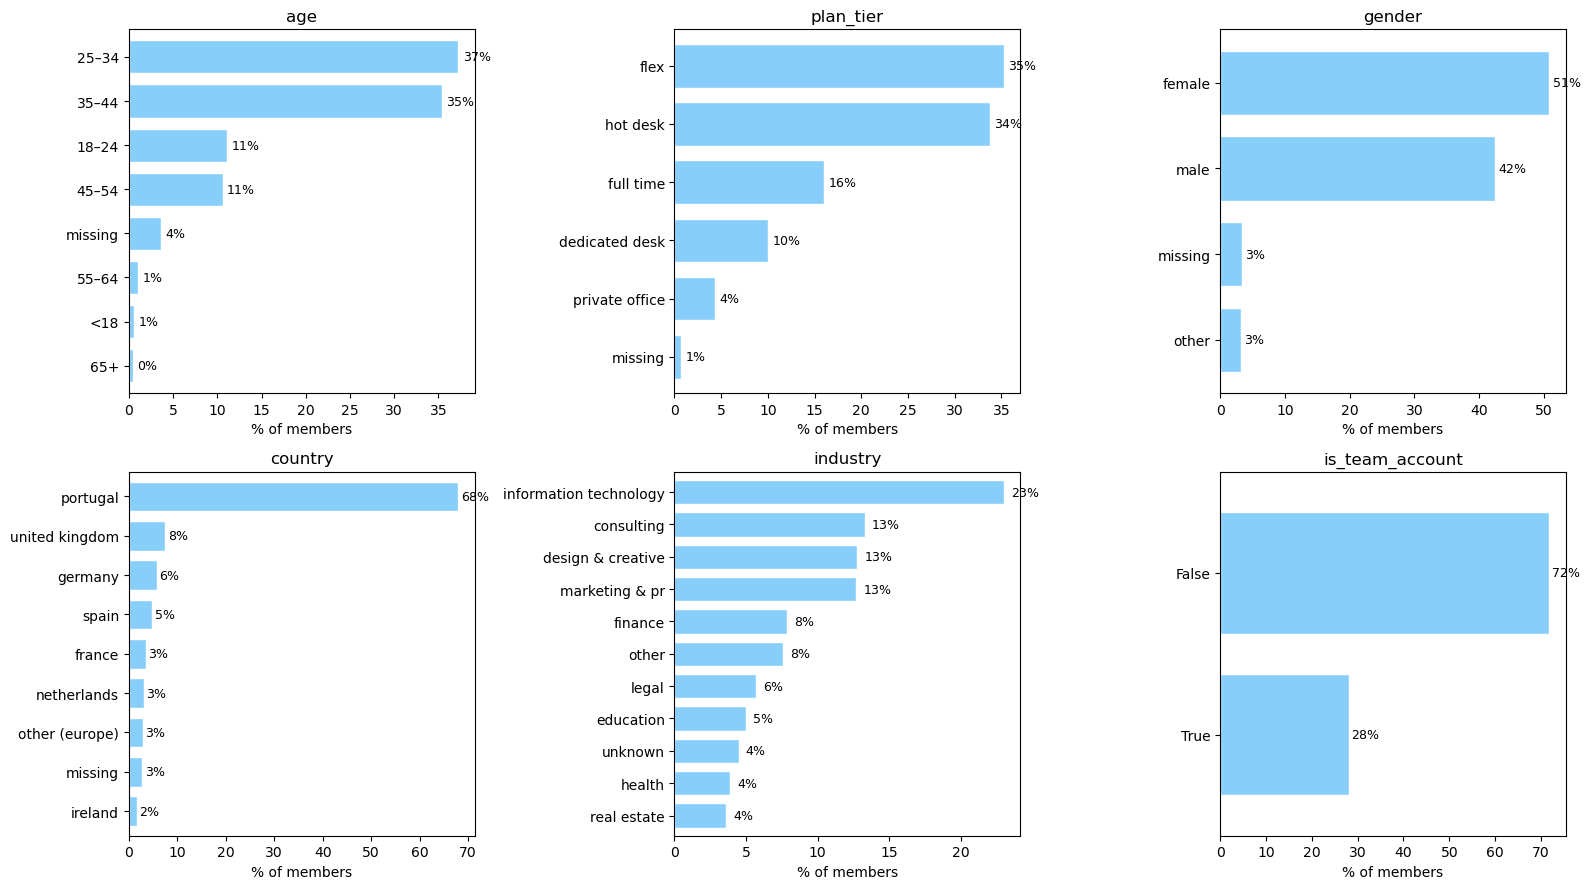

In [193]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9), tight_layout=True)
categories = ['age', 'plan_tier', 'gender', 'country', 'industry', 'is_team_account']
for ax, col in zip(axes.flat, categories):
    if col == 'age':
        age_bins = [0, 18, 25, 35, 45, 55, 65, np.inf]
        age_labels = ['<18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
        age_groups = pd.cut(acdc_dataset['age'], bins=age_bins, labels=age_labels, right=False)
        valcount = age_groups.value_counts(normalize=True, dropna=False, sort=False).mul(100)
    else:
        valcount = acdc_dataset[col].value_counts(normalize=True, dropna=False).mul(100)
    valcount.index = ['missing' if pd.isna(x) else str(x) for x in valcount.index]
    valcount.sort_values().plot.barh(ax=ax, color=Graph_Color[1], edgecolor=Edgecolor[1], width=0.75)
    ax.set_title(col)
    ax.set_xlabel('% of members')
    for p in ax.patches:
        ax.text(p.get_width() + 0.5, p.get_y() + p.get_height() / 2, f'{p.get_width():.0f}%', va='center', fontsize=9, color='black')

plt.show()

- age group follows a normal distribution, however there are a few outliers with impossible and missing values which should be addressed in the next steps.
- almost 70% of plans are betweenthe cheapest options of flex and hot desk, which makes sense, since most user accounts are held by individuals.
- most users are from Portugal and work in IT, consulting, marketing or similar jobs which require office usage.
- regarding gender distribution we observe a slight majority towards female but not by much being amost equally distributed.

## Member activity

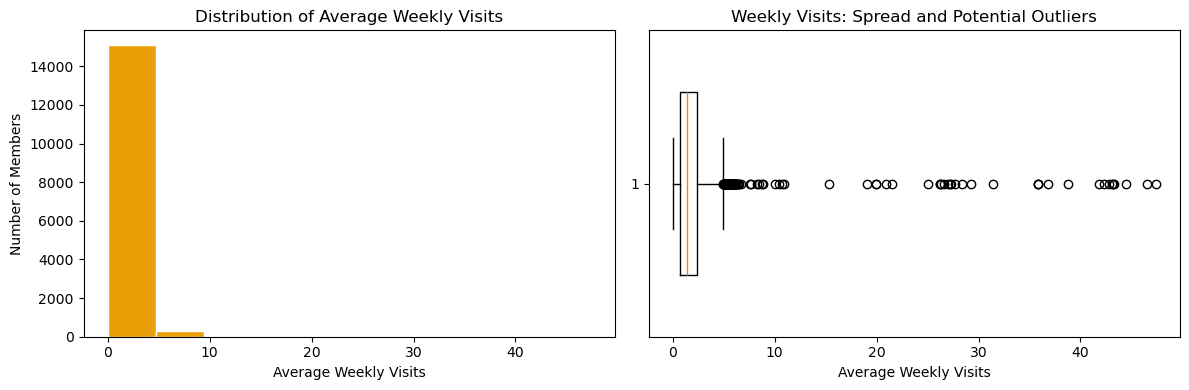

In [194]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), tight_layout=True)

axes[0].hist(acdc_dataset['avg_weekly_visits'].dropna(), bins=10, edgecolor=Edgecolor[1], color= Graph_Color[0])
axes[0].set_title('Distribution of Average Weekly Visits')
axes[0].set_xlabel('Average Weekly Visits')
axes[0].set_ylabel('Number of Members')

axes[1].boxplot(acdc_dataset['avg_weekly_visits'].dropna(), vert=False, widths=0.6)
axes[1].set_title('Weekly Visits: Spread and Potential Outliers')
axes[1].set_xlabel('Average Weekly Visits')

plt.show()

Average weekly visits captures the regular intensity of workspace use and is more comparable across members than total visits alone, since memberships may have different durations. 
- The graphs show that most users have a number of visits between 0 and 5 as expect, most users probably use the service at most once a day.
- The boxplot reveals that there are some outliers who use the service a lot more than would be expected. Perhaps the user is being used by several diferent people

## Lifetime value

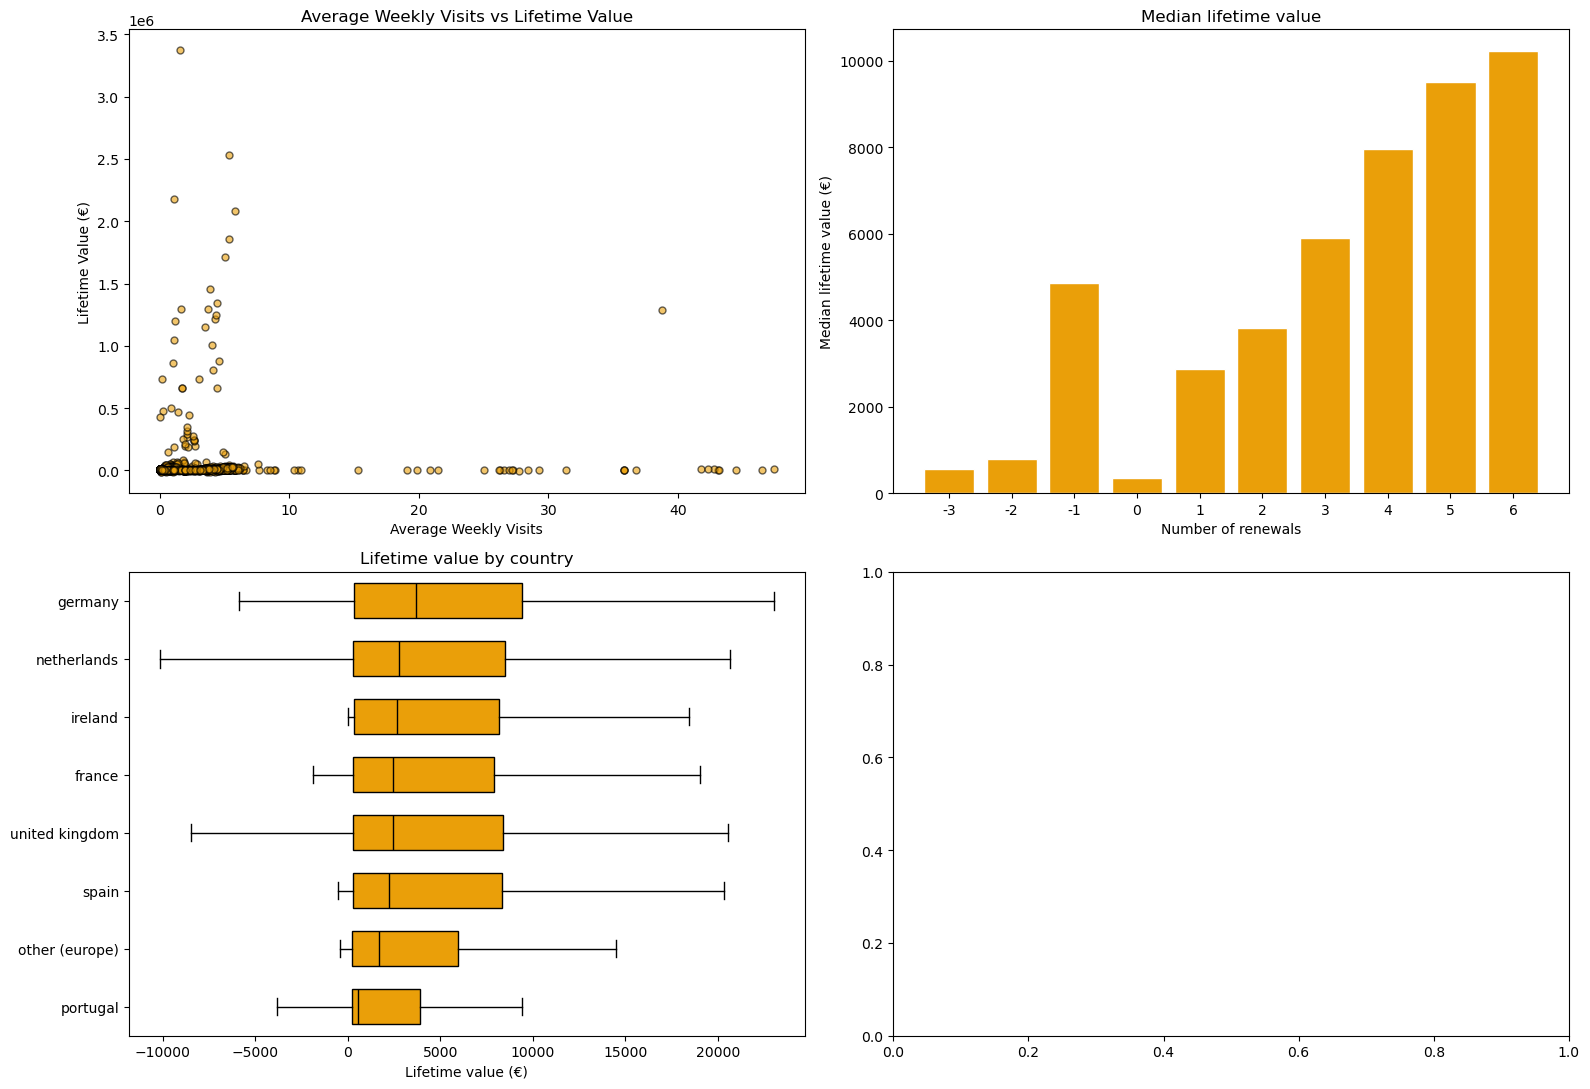

In [206]:
d = acdc_dataset.copy()


fig, axes = plt.subplots(2, 2, figsize=(16, 11))


ax = axes[0, 0]
value_activity = acdc_dataset[['avg_weekly_visits', 'lifetime_value']].dropna()
ax.scatter(
    value_activity['avg_weekly_visits'],
    value_activity['lifetime_value'],
    alpha=0.6,
    color=Graph_Color[0],
    edgecolors=Edgecolor[0],
    s=25
)
ax.set_title('Average Weekly Visits vs Lifetime Value')
ax.set_xlabel('Average Weekly Visits')
ax.set_ylabel('Lifetime Value (€)')


ax = axes[0, 1]
med = d.groupby('n_renewals')['lifetime_value'].median()
ax.bar(
    med.index.astype(int).astype(str), 
    med.values, color=Graph_Color[0], 
    edgecolor=Edgecolor[1]
)
ax.set_xlabel('Number of renewals')
ax.set_ylabel('Median lifetime value (€)')
ax.set_title('Median lifetime value')


ax = axes[1, 0]
order = d.groupby('country')['lifetime_value'].median().sort_values().index
data = [d.loc[d['country'] == c, 'lifetime_value'].dropna() for c in order]
ax.boxplot(
    data, 
    vert=False, 
    showfliers=False, 
    patch_artist=True, 
    widths=0.6,
    boxprops=dict(facecolor=Graph_Color[0]), 
    medianprops=dict(color='black')
)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel('Lifetime value (€)')
ax.set_title('Lifetime value by country')

plt.tight_layout()
plt.show()

### Lifetime value per plan tier

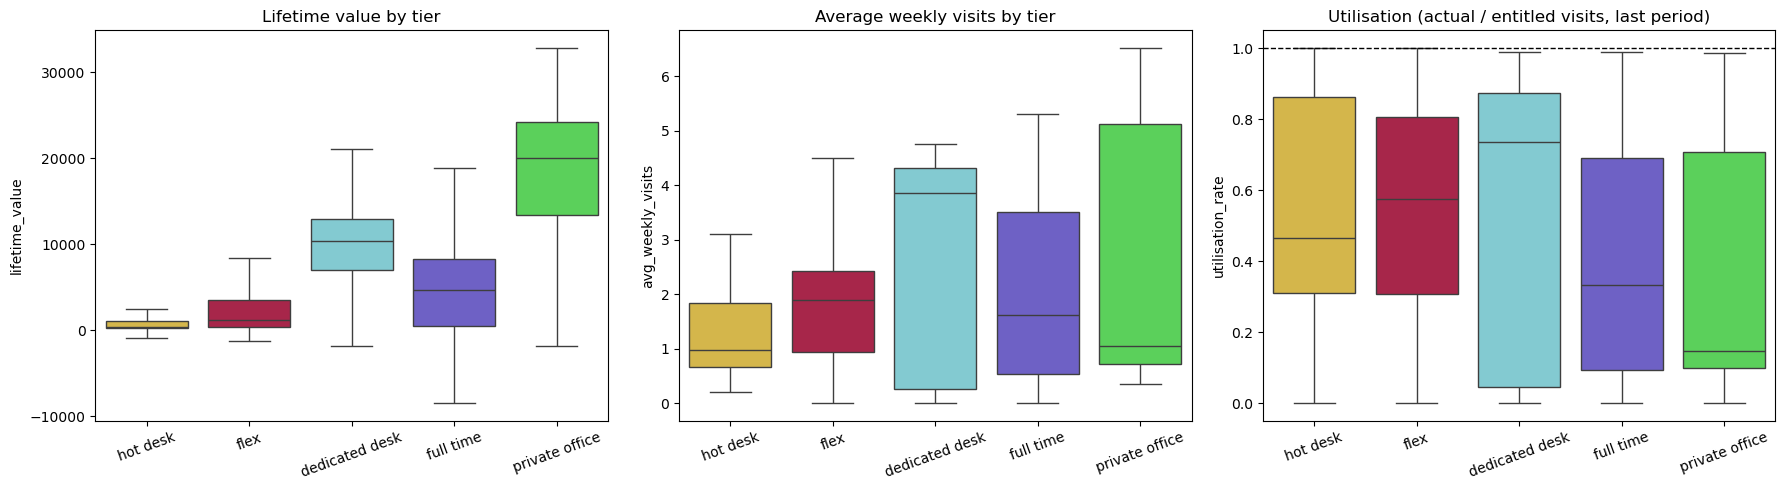

,members,median_ltv,median_weekly_visits,median_utilisation
plan_tier,,,,
hot desk,5212,318.470,0.965,0.464576
flex,5449,1153.430,1.890,0.574933
dedicated desk,1549,10348.025,3.860,0.735971
full time,2471,4613.155,1.610,0.333048
private office,664,19984.240,1.040,0.147856


In [196]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=acdc_dataset, x='plan_tier', y='lifetime_value', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[0], showfliers=False)
axes[0].set_title('Lifetime value by tier')
sns.boxplot(data=acdc_dataset, x='plan_tier', y='avg_weekly_visits', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[1], showfliers=False)
axes[1].set_title('Average weekly visits by tier')
util = acdc_dataset.actual_visits_last_period / acdc_dataset.entitled_visits_last_period.replace(0, np.nan)
sns.boxplot(x=acdc_dataset.plan_tier, y=util.clip(upper=2), hue=acdc_dataset.plan_tier, legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[2], showfliers=False)
axes[2].axhline(1, color=Edgecolor[0], ls='--', lw=1)
axes[2].set_title('Utilisation (actual / entitled visits, last period)')
axes[2].set_ylabel('utilisation_rate')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

acdc_dataset.groupby('plan_tier', observed=True).agg(
    members=('member_id', 'size'),
    median_ltv=('lifetime_value', 'median'),
    median_weekly_visits=('avg_weekly_visits', 'median'),
    median_utilisation=('actual_visits_last_period', lambda s: (s / acdc_dataset.loc[s.index, 'entitled_visits_last_period'].replace(0, np.nan)).median()),
).reindex(Tier_Order)

## Feature engineering: plan utilization

Recent plan utilization compares the number of visits actually made with the number included in the member's plan during the last period. A value of 1 represents full use of the available entitlement, while lower values represent unused capacity.

The executed data show an average utilization rate of approximately 0.52, with the middle 50% of members ranging from about 0.24 to 0.80. This indicates substantial variation in how fully members use the access they purchase and makes utilization a useful behavioral measure for later segmentation. Members with zero entitlement are left undefined to avoid creating an artificial ratio.


In [197]:
acdc_dataset['visit_utilization_rate'] = np.where(
    acdc_dataset['entitled_visits_last_period'] > 0,
    acdc_dataset['actual_visits_last_period'] / acdc_dataset['entitled_visits_last_period'],
    np.nan
)

acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period', 'visit_utilization_rate']].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
entitled_visits_last_period,15450.0,27.51,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15450.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
visit_utilization_rate,15440.0,0.52,0.31,0.0,0.24,0.52,0.80,1.00


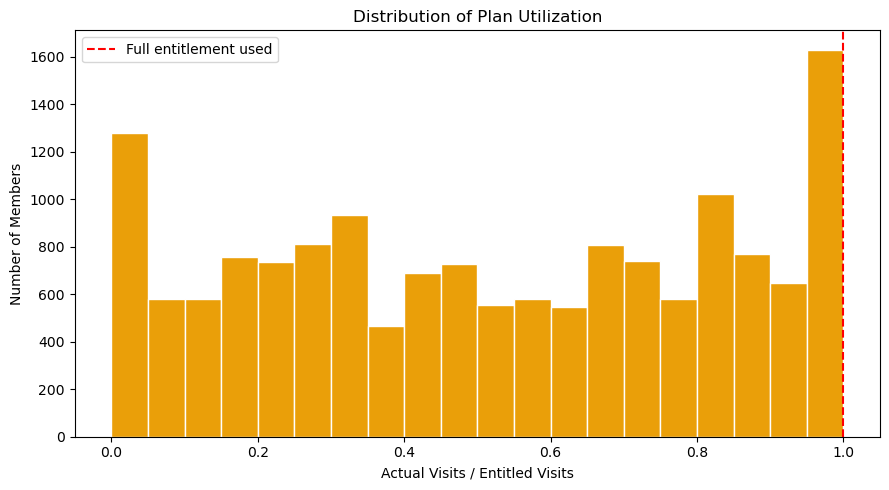

In [198]:
utilization = acdc_dataset['visit_utilization_rate'].replace([np.inf, -np.inf], np.nan).dropna()

plt.figure(figsize=(9, 5))
plt.hist(utilization, bins=20, edgecolor=Edgecolor[1], color=Graph_Color[0],                                 )
plt.axvline(1, linestyle='--', color='red', linewidth=1.5, label='Full entitlement used')
plt.title('Distribution of Plan Utilization')
plt.xlabel('Actual Visits / Entitled Visits')
plt.ylabel('Number of Members')
plt.legend()
plt.tight_layout()
plt.show()

This graphs shows that most users pay but do not fully utilize their weekly entitled visits

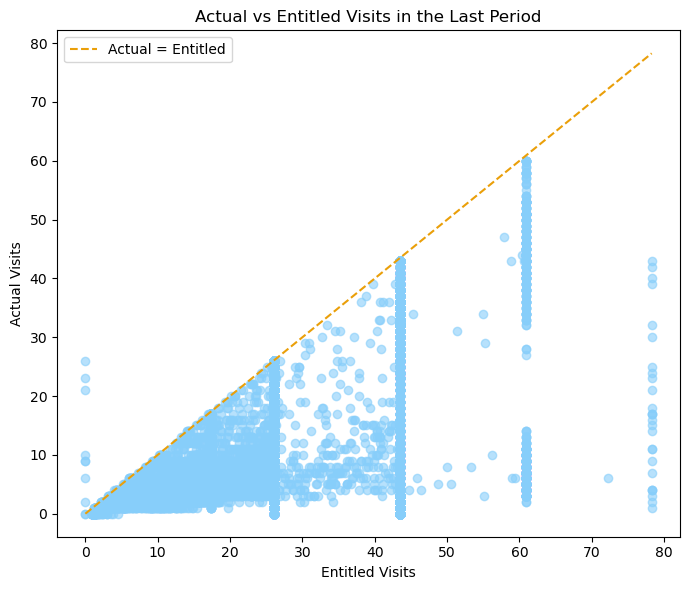

In [208]:
visit_comparison = acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period']].dropna()

plt.figure(figsize=(7, 6))
plt.scatter(
    visit_comparison['entitled_visits_last_period'],
    visit_comparison['actual_visits_last_period'],
    alpha=0.6,
    color=Graph_Color[1]
)

max_value = visit_comparison.max().max()
plt.plot([0, max_value], [0, max_value], linestyle='--', color=Graph_Color[0], label='Actual = Entitled')
plt.title('Actual vs Entitled Visits in the Last Period')
plt.xlabel('Entitled Visits')
plt.ylabel('Actual Visits')
plt.legend()
plt.tight_layout()
plt.show()

## Use of additional services

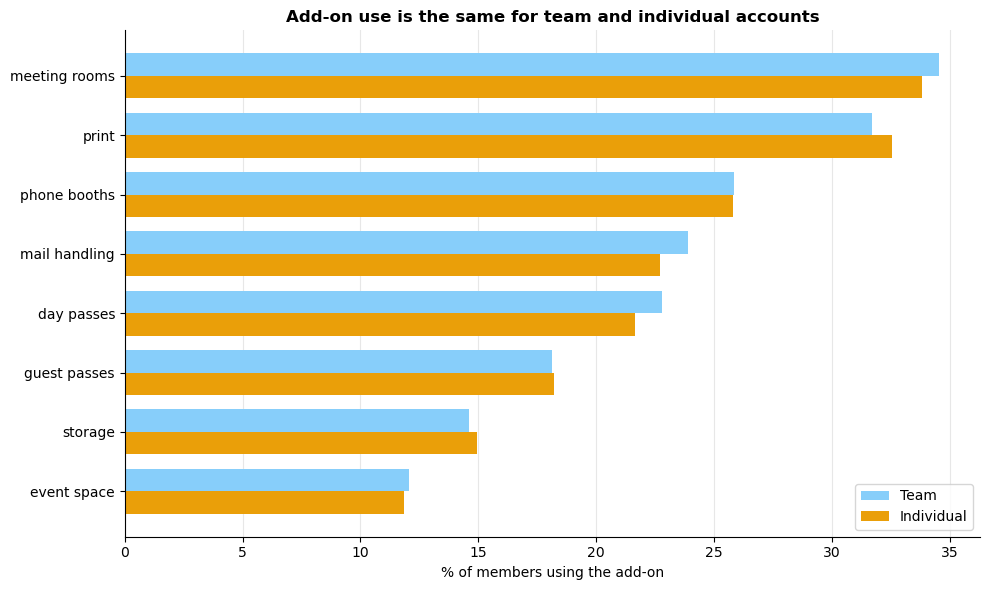

In [200]:
addons = ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
          'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage']

adoption = (acdc_dataset.groupby('is_team_account')[addons].mean().mul(100).T
            .rename(columns={False: 'Individual', True: 'Team'}))
adoption.index = [a.replace('uses_', '').replace('_', ' ') for a in adoption.index]
adoption = adoption.sort_values('Individual')

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(adoption))
h = 0.38
ax.barh(y + h/2, adoption['Team'], height=h, color=Graph_Color[1], label='Team')
ax.barh(y - h/2, adoption['Individual'], height=h, color=Graph_Color[0], label='Individual')
ax.set_yticks(y)
ax.set_yticklabels(adoption.index)
ax.set_xlabel('% of members using the add-on')
ax.set_title('Add-on use is the same for team and individual accounts', fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

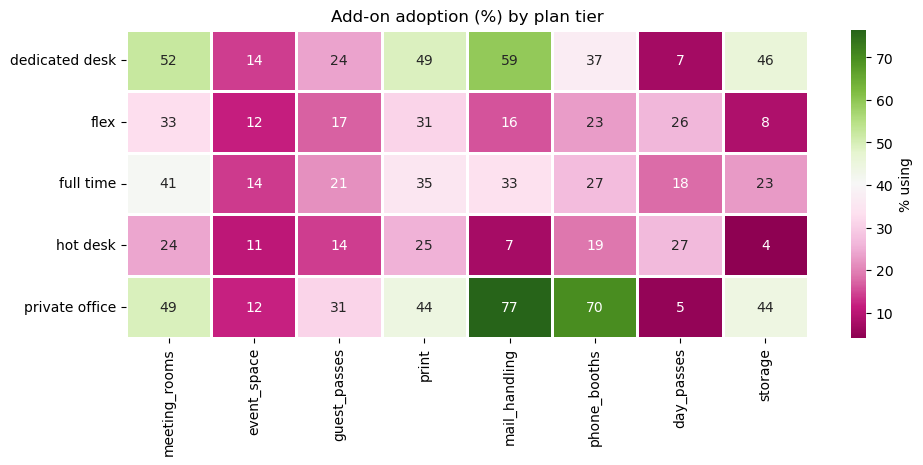

In [201]:
heat = acdc_dataset.groupby('plan_tier', observed=True)[addons].mean().mul(100)
heat.columns = [c.replace('uses_', '') for c in heat.columns]
plt.figure(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt='.0f', cmap=Heatmap[0], cbar_kws={'label': '% using'}, linewidths=2, linecolor=Edgecolor[1])
plt.title('Add-on adoption (%) by plan tier')
plt.ylabel('')
plt.show()

## Team accounts versus individual accounts

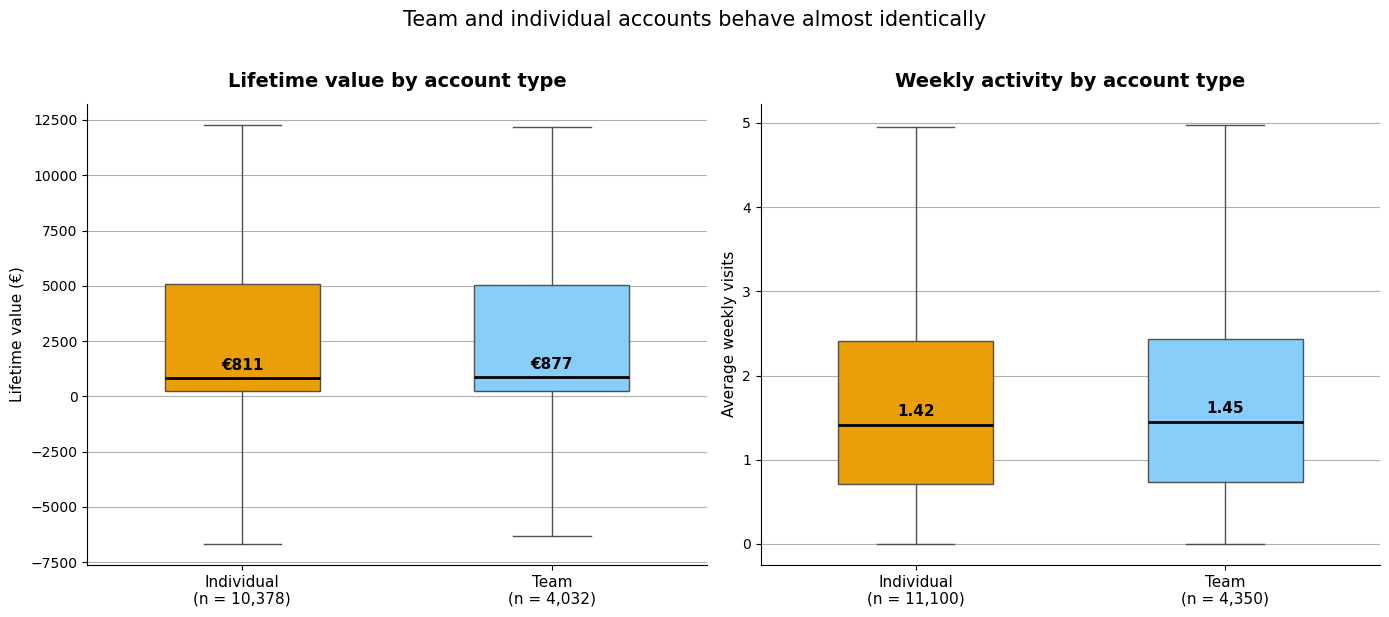

In [202]:
def normalize_boolean(series):
    if pd.api.types.is_bool_dtype(series):
        return series.astype('boolean')
    mapping = {
        'true': True, '1': True, 'yes': True, 'y': True,
        'false': False, '0': False, 'no': False, 'n': False
    }
    return series.astype(str).str.strip().str.lower().map(mapping).astype('boolean')

team_labels = {False: 'Individual', True: 'Team'}
team_series = normalize_boolean(acdc_dataset['is_team_account'])

comparison_df = acdc_dataset[['lifetime_value', 'avg_weekly_visits']].copy()
comparison_df['account_type'] = team_series.map(team_labels)
comparison_df = comparison_df.dropna(subset=['account_type'])

labels = ['Individual', 'Team']
colors = [Graph_Color[0], Graph_Color[1]]
metrics = [
    ('lifetime_value', 'Lifetime value by account type', 'Lifetime value (€)', '€{:,.0f}'),
    ('avg_weekly_visits', 'Weekly activity by account type', 'Average weekly visits', '{:.2f}'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (col, title, ylabel, fmt) in zip(axes, metrics):
    groups = [comparison_df.loc[comparison_df['account_type'] == l, col].dropna() for l in labels]

    bp = ax.boxplot(groups, patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color='black', linewidth=2),
                    whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor('#52514e')

    for i, g in enumerate(groups, start=1):
        ax.annotate(fmt.format(g.median()), xy=(i, g.median()), xytext=(0, 6),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')

    ax.set_xticks([1, 2])
    ax.set_xticklabels([f'{l}\n(n = {len(g):,})' for l, g in zip(labels, groups)], fontsize=11)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

fig.suptitle('Team and individual accounts behave almost identically', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

- observing both graphs shows that both team and individuals have aproximatly the same lifetime value and the sames average visits per week.

## Correlation between numerical segmentation variables

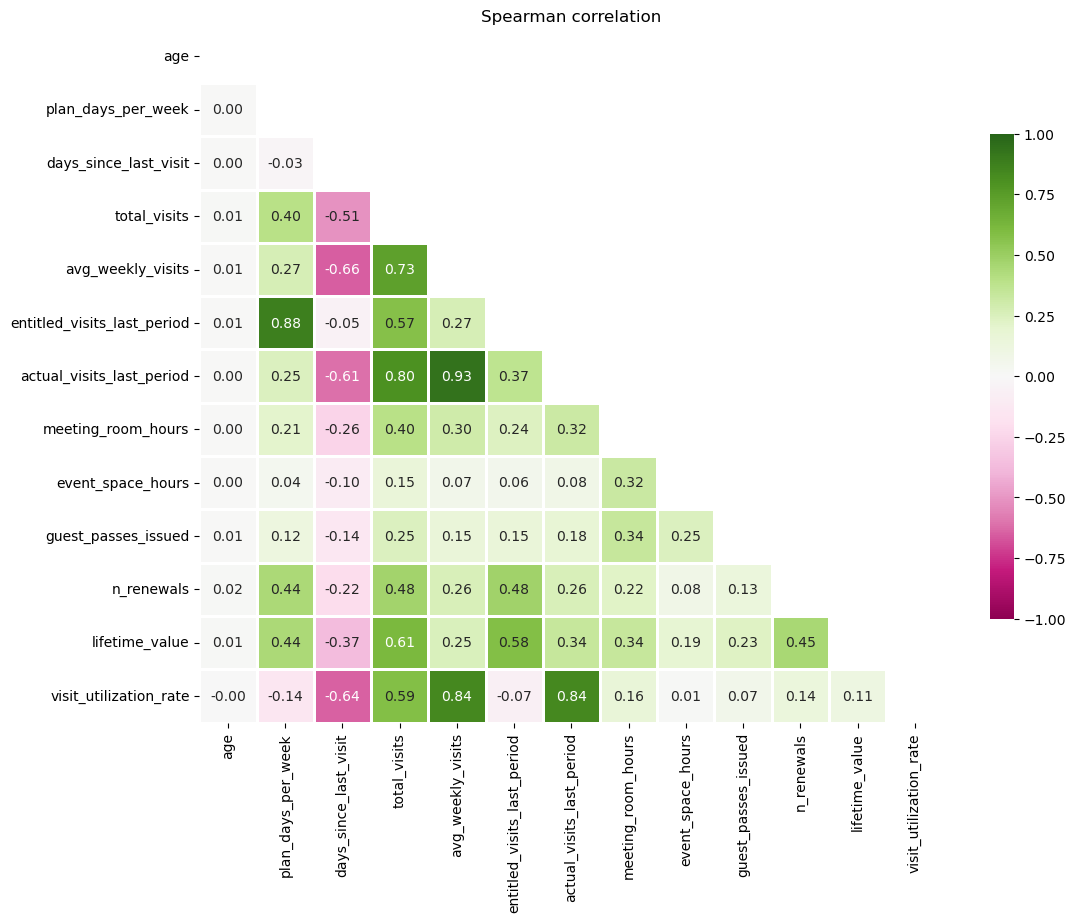

In [203]:
corr_cols =  [
    'age', 'plan_days_per_week', 'days_since_last_visit', 'total_visits',
    'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period',
    'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
    'n_renewals', 'lifetime_value', 'visit_utilization_rate'
]
corr = acdc_dataset[corr_cols].corr(method='spearman')
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor='white', cbar_kws={'shrink': .7})
plt.title('Spearman correlation')
plt.show()

- We can observe that most feature relating to visit count have a strong correlation, as would be expected. Perhaps some of these features may be redundant and could be eleiminated in next steps.
- ltv has, as expected, some positive correlation with visit count features, and we can also see that it has a negative correlation with the more days pass since last visit.
- Age does not seem to have any correlation with any of the other numeric features.